In [51]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [52]:
def gradient_step(w, y_true, X, lr):
    n = X.shape[0]
    e = X @ w - y_true
    grad = (2 / n) * ((X.T) @ e)
    return w - lr * grad

def mse(y_pred, y_true):
    return np.sum((y_pred - y_true) ** 2) / y_pred.shape[0]

In [53]:
features = ["w0", "temperature", "calibration_error", "hour", "control_a", "control_b"]

def format(table):
    table.insert(0, column="w0", value=np.ones(len(table)))
    X = np.array(table[features])
    y_true = np.array(table["target"])
    X_std = X.std(axis = 0)
    X_mean = X.mean(axis = 0)
    X_mean[0] = 0
    X_std[0] = 1
    X_norm = (X - X_mean) / X_std
    y_true_norm = (y_true - (y_true.mean())) / (y_true.std())
    return X, y_true, X_norm, y_true_norm, y_true.mean(), y_true.std(), X_mean, X_std

[ 2.29505304e-16  3.20860874e-03  4.85330226e-03  3.33438824e-03
 -2.96202925e-03 -8.55462304e-03]


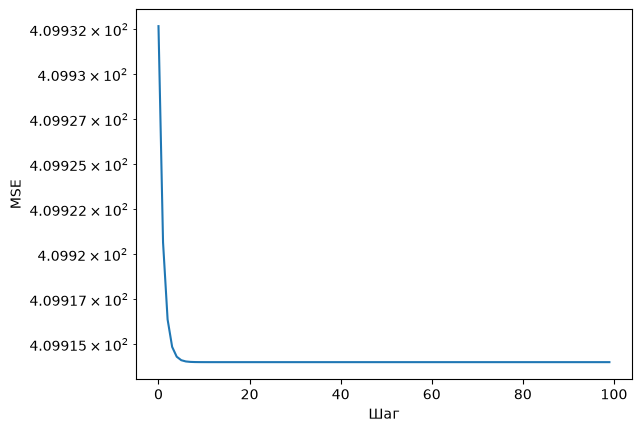

409.93268227683444
409.91400596834666


In [54]:
train = pd.read_csv("train.csv")
X, y_true, X_norm, y_true_norm, y_mean, y_std, X_mean, X_std = format(train)
w = np.zeros(6)
history = []
for i in range(100):
    w = gradient_step(w, y_true_norm, X_norm, 0.2)
    prediction = X_norm @ w
    history.append(mse(prediction * y_std + y_mean, y_true))
print(w)
plt.plot(history)
plt.yscale("log")
plt.xlabel("Шаг")
plt.ylabel("MSE")
plt.show()
print(history[0])
print(history[-1])

In [55]:
valid = pd.read_csv("validation.csv")
valid.insert(0, column="w0", value=np.ones(len(valid)))
X_valid = np.array(valid[features])
X_valid_norm = (X_valid - X_mean) / X_std
prediction_valid = (X_valid_norm @ w) * y_std + y_mean
y_valid = valid["target"]
print(mse(prediction_valid, y_valid))

407.67971604045636


In [56]:
test = pd.read_csv("test.csv")
test.insert(0, column="w0", value=np.ones(len(test)))
X_test = np.array(test[features])
X_test_norm = (X_test - X_mean) / X_std
prediction_test = (X_test_norm @ w) * y_std + y_mean
submission = pd.read_csv("sample_submission.csv")
submission["target"] = prediction_test
submission.to_csv("../submission.csv", index=False)